# Stallman Method for Pumping Tests with Hydraulic Boundaries

*Hydraulic Methods | KIT*

**Objective:** Understand how constant-head and no-flow boundaries affect pumping-test drawdown and estimate **T**, **S**, and **P** from observations.

We start with the Theis solution and the image-well method, generate type curves, and then analyze synthetic data and an exercise dataset. **NumPy, SciPy, and Matplotlib** are required. The type-curve implementation follows T. N. Olsthoorn ([example code](https://transientgroundwaterflow.readthedocs.io/en/latest/WellInLeakyAquifer.html)).

## 1. The Theis equation

The drawdown **s** at distance **r** from a well pumping at constant rate **Q** is given by the Theis equation:

$$
s(u)=\frac{Q}{4\pi T}W(u), \qquad u=\frac{r^2 S}{4Tt}.
$$

Here **T** is transmissivity (m²/s), **S** is the dimensionless storage coefficient, and **t** is time since pumping began (s). The well function is

$$
W(u)=\int_u^\infty \frac{e^{-x}}{x}\,dx=E_1(u).
$$

## 2. Stallman: aquifers with hydraulic boundaries

The *image-well method* adds an imaginary well to the actual pumping well. For a **positive (recharge) boundary condition** (e.g. a river with constant hydraulic head), the imaginary well represents injection and its drawdown is subtracted. A **negative (no-flow) boundary condition** is represented by an additional pumping well.

$$
s(t)=\frac{Q}{4\pi T}\left[W(u_r)\mp W(u_i)\right],
$$

$$
u_r=\frac{r_r^2S}{4Tt},\qquad u_i=\frac{r_i^2S}{4Tt},\qquad P=\frac{r_i}{r_r}.
$$

Use the minus sign for positive and the plus sign for negative boundary conditions. **rᵣ** and **rᵢ** are observation-point distances from the real and image wells. For **P → ∞**, the boundary has no effect and the solution approaches Theis. The model assumes an idealized straight boundary.

**Model assumptions:** homogeneous, isotropic, confined aquifer with constant transmissivity; constant pumping rate; idealized straight boundary. Well losses are neglected. **P** is the ratio of the two distances and is dimensionless. The parameter estimation below assumes a **constant-head (recharge) boundary**.

### 2.1 Functions and type curves

First we define the well functions and generate type curves for several values of **P**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import exp1
from scipy.optimize import least_squares

plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

def calc_ur(rr, S, T, t):
    """Dimensionless time parameter for the real well."""
    return rr**2 * S / (4 * T * np.asarray(t))

def calc_ri(rr, P):
    """Distance between observation well and image well: ri = P * rr."""
    return P * rr

def calc_ui(ri, S, T, t):
    """Dimensionless time parameter for the image well."""
    return ri**2 * S / (4 * T * np.asarray(t))

def W(u):
    """Theis well function W(u) = E1(u)."""
    return exp1(u)

def stallman_drawdown_pos(t, S, T, Q, rr, P):
    """Drawdown for positive (recharge) boundary."""
    ur = calc_ur(rr, S, T, t)
    ui = calc_ui(calc_ri(rr, P), S, T, t)
    return Q / (4 * np.pi * T) * (W(ur) - W(ui))

def stallman_drawdown_neg(t, S, T, Q, rr, P):
    """Drawdown for negative (no-flow) boundary."""
    ur = calc_ur(rr, S, T, t)
    ui = calc_ui(calc_ri(rr, P), S, T, t)
    return Q / (4 * np.pi * T) * (W(ur) + W(ui))

Ps = [1.1, 1.2, 1.4, 2, 4, 8, 16, 32, 64, 128]
ur_grid = np.logspace(-7, 1, 201)


The type curves are displayed on log–log axes. For positive boundary conditions, the difference between well functions may become very small for small **P**.

The following plot first shows the type curves for **positive and negative hydraulic boundaries together**. Solid lines represent positive boundary conditions; dashed lines represent negative boundary conditions. Separate plots follow for readability.

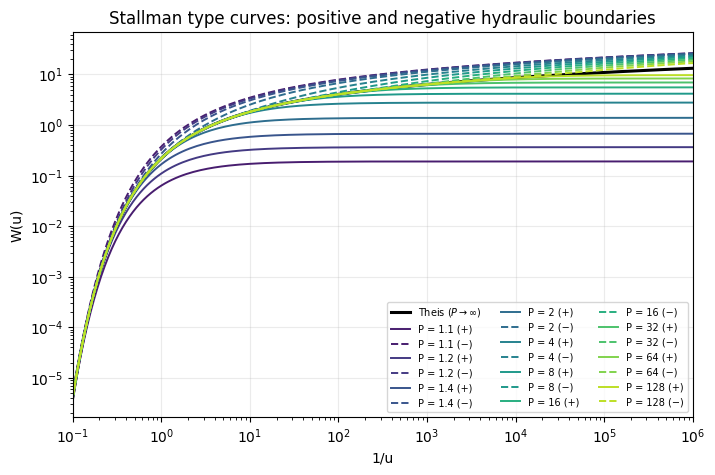

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(1 / ur_grid, W(ur_grid), color='black', linewidth=2.2,
        label=r'Theis ($P \to \infty$)')
colors = plt.cm.viridis(np.linspace(0.08, 0.9, len(Ps)))
for P, color in zip(Ps, colors):
    wi = W(ur_grid * P**2)
    ax.plot(1 / ur_grid, W(ur_grid) - wi, '-', color=color, linewidth=1.4,
            label=f'P = {P:g} (+)')
    ax.plot(1 / ur_grid, W(ur_grid) + wi, '--', color=color, linewidth=1.4,
            label=f'P = {P:g} (−)')
ax.set(xscale='log', yscale='log', xlim=(1e-1, 1e6),
       xlabel='1/u', ylabel='W(u)', title='Stallman type curves: positive and negative hydraulic boundaries')
ax.legend(fontsize=7, ncol=3, loc='best')
plt.show()

**Separate plots for positive and negative boundary conditions:**

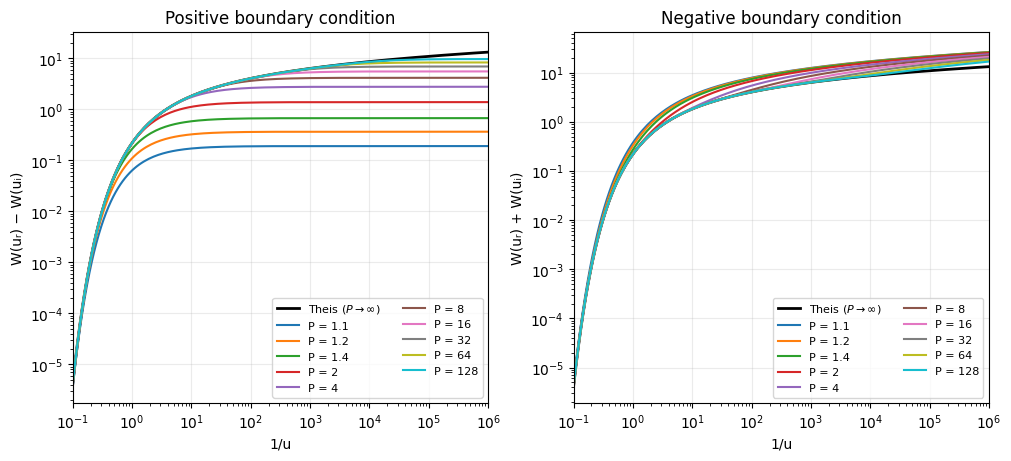

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
for ax, positive in zip(axs, (True, False)):
    ax.plot(1/ur_grid, W(ur_grid), 'k-', linewidth=2, label=r'Theis ($P \to \infty$)')
    for P in Ps:
        wi = W(ur_grid * P**2)
        response = W(ur_grid) - wi if positive else W(ur_grid) + wi
        ax.plot(1/ur_grid, response, label=f'P = {P:g}')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xlabel('1/u'); ax.set_ylabel('W(uᵣ) − W(uᵢ)' if positive else 'W(uᵣ) + W(uᵢ)')
    ax.set_title(('Positive boundary condition' if positive else 'Negative boundary condition'))
    ax.legend(fontsize=8, ncol=2)
plt.show()

For negative boundary conditions, the type curves lie close together, making a purely graphical determination of **P** difficult.

## 3. Synthetic pumping test

We generate measurements for a positive boundary condition at **P = 5**. The time series and parameters follow the exercise. A fixed random seed makes measurement noise reproducible.

**Workflow:** First we inspect the observations on linear axes; fitted model curves are then shown on log–log axes.

In [4]:
Q = 0.01            # m³/s
r = 10.0            # m
S_true = 0.001      # dimensionless
T_true = 0.001      # m²/s
P_true = 5.0

t = np.array([150, 200, 300, 400, 600, 800, 1000, 1400, 1800,
              2400, 3200, 4800, 6000, 8000, 10000, 20000, 30000], dtype=float)

rng = np.random.default_rng(42)
s_clean = stallman_drawdown_pos(t, S_true, T_true, Q, r, P_true)
noise_sd = 2e-3
s = s_clean * (1 + noise_sd * rng.standard_normal(len(t)))
print(np.round(s, 5))

[1.09201 1.28035 1.55068 1.72667 1.93205 2.06218 2.15253 2.25499 2.31837
 2.37123 2.42381 2.46914 2.48436 2.50865 2.51687 2.53346 2.54755]


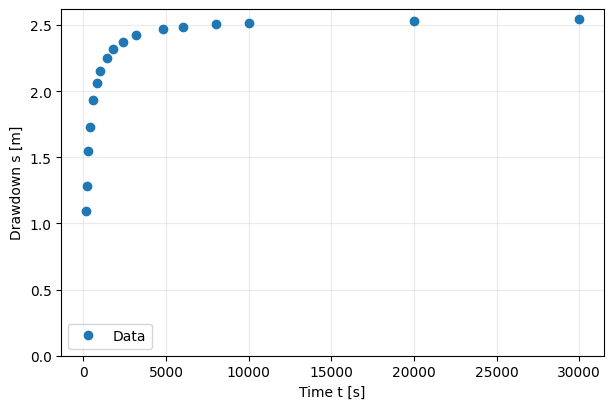

In [5]:
fig, ax = plt.subplots()
ax.plot(t, s, 'o', label='Data')
ax.set_xlabel('Time t [s]')
ax.set_ylabel('Drawdown s [m]')
ax.set_ylim(bottom=0)
ax.legend()
plt.show()

## 4. Nonlinear fitting

As in the exercise, we estimate **S** and **T** by minimizing squared residuals. For numerical stability, we optimize logarithms of the parameters, which keeps **S** and **T** positive. The fit uses known pumping rate **Q**, observation distance **r**, and initially a specified **P**.

**RMSE** is the root mean square error of the residuals (in m). Here, a smaller RMSE indicates a closer fit to the observed data.

P=  5.0: S=1.0024e-03, T=9.9967e-04 m²/s, RMSE=0.00352 m


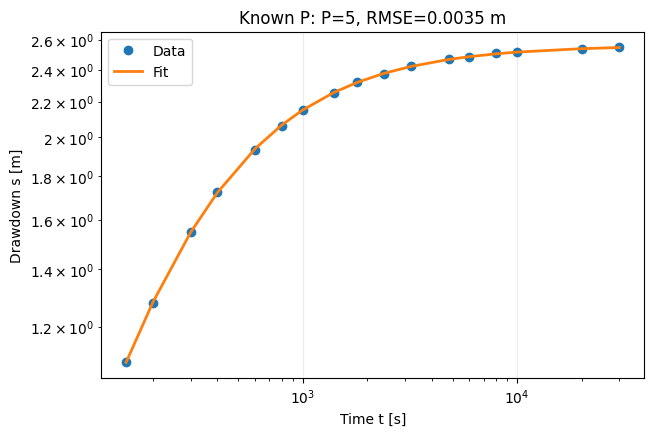

In [6]:
def fit_stallman(t, s, Q, r, P, guess=(1e-3, 1e-3)):
    """Fit positive-boundary Stallman curve; return S, T, RMSE, fitted curve."""
    t = np.asarray(t, dtype=float)
    s = np.asarray(s, dtype=float)
    def residual(log_params):
        S, T = np.exp(log_params)
        return stallman_drawdown_pos(t, S, T, Q, r, P) - s
    result = least_squares(residual, np.log(guess), bounds=(np.log([1e-9, 1e-9]), np.log([1, 1])))
    Sfit, Tfit = np.exp(result.x)
    fit = stallman_drawdown_pos(t, Sfit, Tfit, Q, r, P)
    rmse = np.sqrt(np.mean((s - fit)**2))
    return Sfit, Tfit, rmse, fit

def search_P(P_values, t, s, Q, r, verbose=True):
    """Compare candidate P values by RMSE; return best-fit dictionary."""
    results = []
    for P in P_values:
        Sfit, Tfit, rmse, fit = fit_stallman(t, s, Q, r, float(P))
        results.append(dict(P=float(P), S=Sfit, T=Tfit, rmse=rmse, fit=fit))
        if verbose:
            print(f'P={P:5.1f}: S={Sfit:.4e}, T={Tfit:.4e} m²/s, RMSE={rmse:.5f} m')
    return min(results, key=lambda result: result['rmse'])

def plot_fit(t, s, result, heading):
    fig, ax = plt.subplots()
    ax.plot(t, s, 'o', label='Data')
    ax.plot(t, result['fit'], '-', label='Fit', linewidth=2)
    ax.set_xlabel('Time t [s]')
    ax.set_ylabel('Drawdown s [m]')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f"{heading}: P={result['P']:g}, RMSE={result['rmse']:.4f} m")
    ax.legend()
    plt.show()

best_known = search_P([5], t, s, Q, r)
plot_fit(t, s, best_known, 'Known P')

The estimated values should be close to the parameters used to generate the data.

### 4.1 Searching for P when boundary position is unknown

If **P** is unknown, we fit **S** and **T** for candidate values and select the smallest RMSE. First, we use a coarse grid.

P=  1.1: S=3.0628e-04, T=6.0150e-05 m²/s, RMSE=0.04127 m
P=  1.2: S=5.3641e-04, T=1.1504e-04 m²/s, RMSE=0.04086 m
P=  1.4: S=8.4509e-04, T=2.1219e-04 m²/s, RMSE=0.03953 m
P=  2.0: S=1.1964e-03, T=4.3603e-04 m²/s, RMSE=0.03349 m
P=  4.0: S=1.1148e-03, T=8.6425e-04 m²/s, RMSE=0.01124 m
P=  8.0: S=7.4419e-04, T=1.2809e-03 m²/s, RMSE=0.02221 m
P= 16.0: S=4.2228e-04, T=1.6864e-03 m²/s, RMSE=0.05798 m
P= 32.0: S=2.1703e-04, T=2.0817e-03 m²/s, RMSE=0.09209 m
P= 64.0: S=1.0553e-04, T=2.4648e-03 m²/s, RMSE=0.12232 m
P=128.0: S=5.0737e-05, T=2.8279e-03 m²/s, RMSE=0.14826 m
Best value: P=4


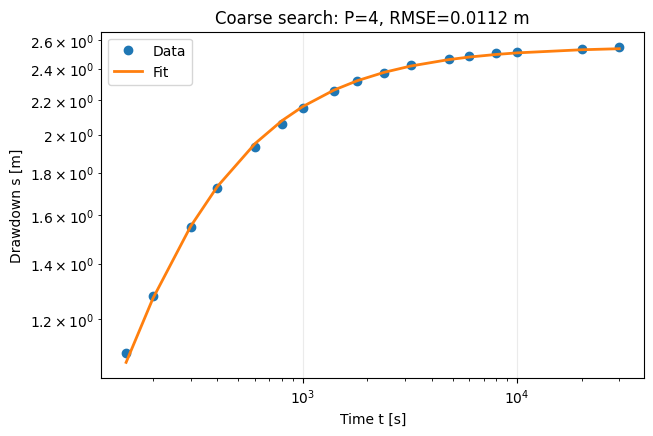

In [7]:
P_coarse = np.array([1.1, 1.2, 1.4, 2, 4, 8, 16, 32, 64, 128])
best_coarse = search_P(P_coarse, t, s, Q, r)
print(f"Best value: P={best_coarse['P']:g}")
plot_fit(t, s, best_coarse, 'Coarse search')

Next, we refine the search grid over **P = 4 to 8**.

P=  4.0: S=1.1148e-03, T=8.6425e-04 m²/s, RMSE=0.01124 m
P=  5.0: S=1.0024e-03, T=9.9967e-04 m²/s, RMSE=0.00352 m
P=  6.0: S=9.0241e-04, T=1.1094e-03 m²/s, RMSE=0.00832 m
P=  7.0: S=8.1690e-04, T=1.2015e-03 m²/s, RMSE=0.01557 m
P=  8.0: S=7.4419e-04, T=1.2809e-03 m²/s, RMSE=0.02221 m
Best value: P=5


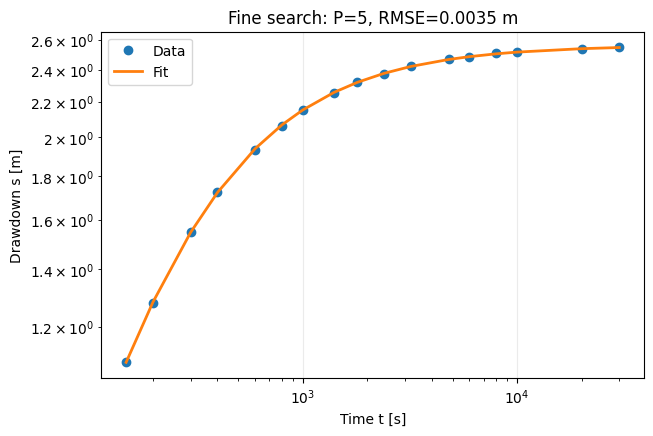

In [8]:
P_fine = np.array([4, 5, 6, 7, 8])
best_fine = search_P(P_fine, t, s, Q, r)
print(f"Best value: P={best_fine['P']:g}")
plot_fit(t, s, best_fine, 'Fine search')

The best result is at **P = 5**, the value specified for the synthetic example.

## 5. Exercise with measured pumping-test data

The exercise specifies **Q = 6 L/s** and **r = 40 m**. We keep the measurements unchanged, and search first on a coarse and then on a finer grid of **P**, as above.

Again, the measured data are first shown on linear axes, followed by the fitted curves on log–log axes.

In [9]:
Q_ex = 0.006     # m³/s
r_ex = 40.0      # m
t_ex = np.array([10, 18, 32, 56, 100, 178, 316, 562, 1000, 1778,
                 3162, 5623, 10000, 17780, 31620, 56230, 100000, 200000], dtype=float)
s_ex = np.array([0.005, 0.02, 0.05, 0.09, 0.16, 0.23, 0.31, 0.4,
                 0.49, 0.58, 0.67, 0.75, 0.82, 0.87, 0.9, 0.92, 0.93, 0.93])

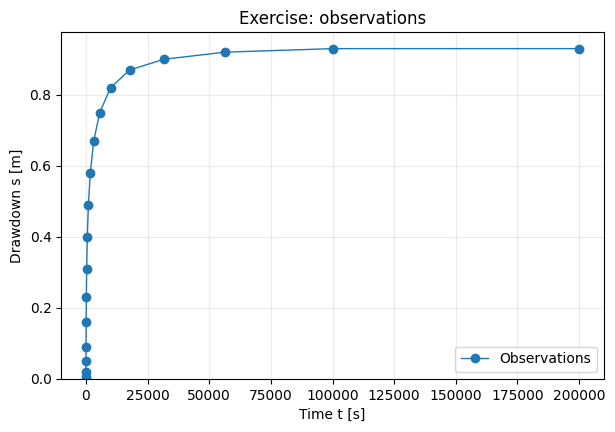

In [10]:
fig, ax = plt.subplots()
ax.plot(t_ex, s_ex, 'o-', linewidth=1, label='Observations')
ax.set(xlabel='Time t [s]', ylabel='Drawdown s [m]', title='Exercise: observations')
ax.set_ylim(bottom=0)
ax.legend()
plt.show()

### 5.1 Coarse search

P=  1.1: S=9.4301e-05, T=1.0543e-04 m²/s, RMSE=0.07568 m
P=  1.2: S=1.6545e-04, T=2.0161e-04 m²/s, RMSE=0.07537 m
P=  1.4: S=2.6218e-04, T=3.7164e-04 m²/s, RMSE=0.07433 m
P=  2.0: S=3.8116e-04, T=7.6174e-04 m²/s, RMSE=0.06970 m
P=  4.0: S=3.9285e-04, T=1.4965e-03 m²/s, RMSE=0.05350 m
P=  8.0: S=3.0920e-04, T=2.1885e-03 m²/s, RMSE=0.03126 m
P= 16.0: S=2.2147e-04, T=2.8282e-03 m²/s, RMSE=0.00683 m
P= 32.0: S=1.5526e-04, T=3.4004e-03 m²/s, RMSE=0.01892 m
P= 64.0: S=1.1460e-04, T=3.8630e-03 m²/s, RMSE=0.04111 m
P=128.0: S=1.0195e-04, T=4.1009e-03 m²/s, RMSE=0.05697 m
Best value: P=16


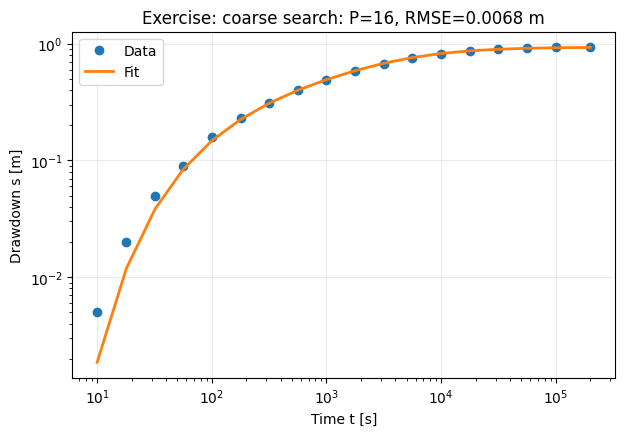

In [11]:
best_ex_coarse = search_P(P_coarse, t_ex, s_ex, Q_ex, r_ex)
print(f"Best value: P={best_ex_coarse['P']:g}")
plot_fit(t_ex, s_ex, best_ex_coarse, 'Exercise: coarse search')

### 5.2 Finer search

We now refine the grid for **P** and compare candidate values between 14 and 32.

Best fit: P=19, S=2.0272e-04, T=2.9773e-03 m²/s, RMSE=0.00287 m


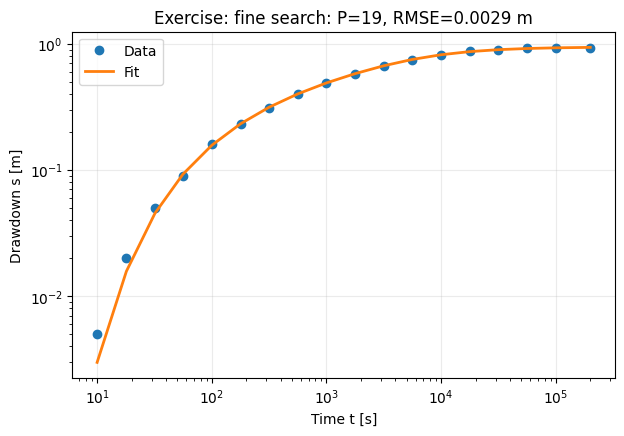

In [12]:
P_ex_fine = np.arange(14, 33)
best_ex = search_P(P_ex_fine, t_ex, s_ex, Q_ex, r_ex, verbose=False)
print(f"Best fit: P={best_ex['P']:.0f}, S={best_ex['S']:.4e}, "
      f"T={best_ex['T']:.4e} m²/s, RMSE={best_ex['rmse']:.5f} m")
plot_fit(t_ex, s_ex, best_ex, 'Exercise: fine search')

The two grids illustrate how boundary location can be estimated through **P**. Results depend on the assumption of an idealized hydraulic boundary. A finer numerical search may improve the fit without necessarily making the hydrogeological interpretation more reliable.

## 6. Results and interpretation

The **coarse search** identifies a plausible range for **P**; the **fine search** selects the lowest root mean square error within that grid. For the exercise data:

| Parameter | Result | Meaning |
|---|---:|---|
| **P** | 19 | image-well distance relative to observation-well distance |
| **T** | approx. 2.98 × 10⁻³ m²/s | transmissivity |
| **S** | approx. 2.03 × 10⁻⁴ | dimensionless storage coefficient |
| **RMSE** | approx. 0.0029 m | fitting error |

**Interpretation:** These results assume an idealized constant-head boundary. A small fitting error alone does not demonstrate the exact boundary location or unique parameter estimates. Boundary type and position should also be evaluated against hydrogeological evidence.

## References

- Theis, C. V. (1935): The relation between the lowering of the piezometric surface and the rate and duration of discharge of a well using ground-water storage. *Transactions, American Geophysical Union*, 16, 519–524.
- Stallman, R. W. (1965): Effects of water-table conditions on water-level changes near pumping wells. *Water Resources Research*, 1, 295–312.
- Olsthoorn, T. N.: [Transient Groundwater Flow – examples](https://transientgroundwaterflow.readthedocs.io/en/latest/WellInLeakyAquifer.html) (code reference).